# Analyze PCR, KBET, and PROBE

In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import scipy
from scipy.cluster.hierarchy import linkage, leaves_list
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt
import sklearn
from itertools import combinations
import colorcet as cc
from sklearn.covariance import MinCovDet
from scipy.stats import chi2
import math

import matplotlib.font_manager as font_manager

font_manager.fontManager.addfont('/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')
prop = font_manager.FontProperties(fname='/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()

import os
import sys
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/')
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scripts/project_utils/')
os.environ["R_HOME"] = "/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/R"

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [2]:
import scib
from scib.metrics import *
from analysis_helpers import *

## Calculate Cramer's V for all datasets

The Cramer's V correlates the two categorical variables of batches and cell types.
Then, correlate it with the correlation between PCR/PROBE and KBET.

In [ ]:
vs = []
for da in runs['dataset'].unique():
    d = runs[runs['dataset'] == da].iloc[0]['workdir']
    adata_int = sc.read(f"{d}/save_dir/adata.h5ad")
    batch_col = dataset_keys[da]['batch_keys'][0]
    celltype_col = dataset_keys[da]['celltype_keys'][0]
    
    confusion_matrix = pd.crosstab(adata_int.obs[batch_col], adata_int.obs[celltype_col])
    chi2 = scipy.stats.chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    r, k = confusion_matrix.shape
    V = np.sqrt(chi2 / (n * (min(k, r) - 1)))
    vs.append((da, V))

In [ ]:
vs = pd.DataFrame(vs, columns=['dataset', 'Cramer\'s V']).set_index('dataset')

In [166]:
vs.to_csv('../results/spreadsheets/cramers_v.csv')

In [3]:
vs = pd.read_csv('../results/spreadsheets/cramers_v.csv').set_index('dataset')

In [4]:
dataset_corrs = pd.read_csv('../results/spreadsheets/kbet_pcr_corr.csv', index_col=0)

In [6]:
join = vs.join(dataset_corrs, how='inner')
join

,Cramer's V,Spearman_Correlation
human_pancreas,0.189765,0.556426
neurips_bmmc,0.245056,0.330803
human_lung,0.429152,0.369265
scib_sim1,0.224562,0.347576
scib_sim2,0.210149,0.365992
seurat_pbmc,0.161076,0.431510
human_fetal_gut,0.320106,0.416258
pan_cancer_dc,0.255777,0.753657
human_eoe,0.189445,0.408499
pan_cancer_b,0.129044,0.697802


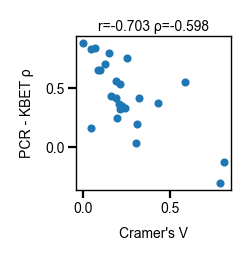

In [7]:
x, y = join["Cramer's V"], join['Spearman_Correlation']
with plt.rc_context({'figure.figsize': (1, 1), 'figure.dpi': 200}):
    fig, ax = plt.subplots()
    ax.scatter(x,y, s=2)
    plt.title(f'r={scipy.stats.pearsonr(x,y).statistic:.3f} ρ={scipy.stats.spearmanr(x,y).statistic:.3f}',
             fontsize=5, pad=2)
    plt.xlabel("Cramer's V", fontsize=5)
    plt.ylabel("PCR - KBET ρ", fontsize=5)
    ax.tick_params(axis='both', which='major', width=.8,
                   length=3,          # Make the ticks slightly shorter
                   labelsize=5,       # Keeping previous larger label size
                   pad=1)
    for spine in ax.spines.values():
        spine.set_linewidth(0.5)
#     plt.savefig(f'../publication_figures/pcr_cramer_v.png', dpi=300, bbox_inches='tight')

    plt.show()

In [8]:
vs = pd.read_csv('../results/spreadsheets/cramers_v.csv').set_index('dataset')

In [9]:
dataset_corrs = pd.read_csv('../results/spreadsheets/kbet_probe_corr.csv', index_col=0)

In [10]:
join = vs.join(dataset_corrs, how='inner')
join

,Cramer's V,Spearman_Correlation
human_pancreas,0.189765,0.706275
neurips_bmmc,0.245056,0.575628
human_lung,0.429152,0.479832
scib_sim1,0.224562,0.678290
scib_sim2,0.210149,0.571763
seurat_pbmc,0.161076,0.560929
human_fetal_gut,0.320106,0.550140
pan_cancer_dc,0.255777,0.831538
human_eoe,0.189445,0.450501
pan_cancer_b,0.129044,0.836996


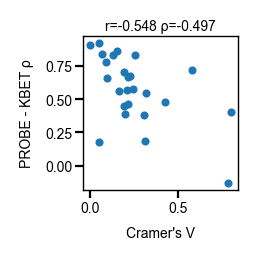

In [11]:
x, y = join["Cramer's V"], join['Spearman_Correlation']
with plt.rc_context({'figure.figsize': (1, 1), 'figure.dpi': 200}):
    fig, ax = plt.subplots()
    ax.scatter(x,y, s=2)
    plt.title(f'r={scipy.stats.pearsonr(x,y).statistic:.3f} ρ={scipy.stats.spearmanr(x,y).statistic:.3f}',
             fontsize=5, pad=2)
    plt.xlabel("Cramer's V", fontsize=5)
    plt.ylabel("PROBE - KBET ρ", fontsize=5)
    ax.tick_params(axis='both', which='major', width=.8,
                   length=3,          # Make the ticks slightly shorter
                   labelsize=5,       # Keeping previous larger label size
                   pad=1)
    for spine in ax.spines.values():
        spine.set_linewidth(0.5)
#     plt.savefig(f'../publication_figures/probe_cramer_v.png', dpi=300, bbox_inches='tight')

    plt.show()

## KBET

This produces the figure on KBET being a fine granularity metric.

In [ ]:
res = calc_kBET_across_labels(adata_int, batch_col, celltype_col, return_means=False)

In [ ]:
pd.DataFrame(res)

In [ ]:
sc.pl.umap(adata_int[adata_int.obs[celltype_col] == 'CD14 monocyte'], color=batch_col)
sc.pl.umap(adata_int[adata_int.obs[celltype_col] == 'Naive CD4 T'], color=batch_col)

In [ ]:
adata_sub = adata_int[adata_int.obs[celltype_col] == 'Naive CD4 T']

In [ ]:
nearestNeighbors = sklearn.neighbors.NearestNeighbors(n_neighbors=70)
nearestNeighbors.fit(adata_sub.obsm['X_integration'])
knn_indices = nearestNeighbors.kneighbors(adata_sub.obsm['X_integration'], return_distance=False)

In [ ]:
(knn_indices[:, 1:]  >= 1429).sum(), knn_indices.shape[0] * knn_indices.shape[1]

In [ ]:
ideal_dist = (
    adata_sub.obs[batch_col].value_counts(normalize=True, sort=False).values
)

In [ ]:
nsample = adata_sub.shape[0]
nbatch = ideal_dist.size
attr_values = adata_sub.obs[batch_col].cat.rename_categories(range(nbatch)).values

In [ ]:
sc.pp.neighbors(adata_sub, use_rep='X_integration')
sc.tl.umap(adata_sub)

In [ ]:
with plt.rc_context({'figure.figsize': (4.1, 4), 'figure.dpi': 250}):
    sc.pl.umap(adata_sub, color=batch_col, title='Batch - Naive CD4 T')

In [ ]:
adata_sub.obs

In [ ]:
np.where((adata_sub.obsp['connectivities'] > 0)[0, :].toarray().flatten())

In [ ]:
counts = []
for i in range(adata_sub.n_obs):
    observed_counts = pd.Series(attr_values[knn_indices[i, :]]).value_counts(sort=False).values
#     observed_counts = pd.Series(attr_values[np.where((adata_sub.obsp['connectivities'] > 0)[i, :].toarray().flatten())]).value_counts(sort=False).values
    counts.append(observed_counts)

In [ ]:
np.where(attr_values == 1)

In [ ]:
with plt.rc_context({'figure.figsize': (5, 3), 'figure.dpi': 250}):
    plt.hist(
        [np.array(counts)[:1429, 0] / 70, np.array(counts)[1429:, 0]/70], 
        bins=35, 
        stacked=True, 
        color=['#1f77b4', '#ff7f0e'], 
        label=['v6', 'v8'],
        edgecolor='white',
        linewidth=0.5
    )
    plt.legend(title='Cell batch')
    plt.xlabel("Proportion of neighbors from v6")
    plt.ylabel('Number of cells')
    plt.show()